# CBE 130 Lab 8: Partial Differential Equations with Explicit Finite Differences

The temperature in a reactor wall and the pressure in a liquid pipeline change with both position and time, so their balances are partial differential equations (PDEs). In this lab, we solve the heat equation and the wave equation by replacing the derivatives with finite differences on a grid and marching forward in time. Explicit schemes like these blow up if the time step is too large, so we choose the time step as a fraction of the largest stable step.

## Learning Objectives

- Estimate the largest stable time step for an explicit scheme and choose a time step with a stability fraction.
- Implement the FTCS scheme for transient heat conduction in a rod.
- Implement the explicit centered scheme, including its special first step, for pressure waves in a pipe.
- Visualize PDE solutions with surface plots and profiles at fixed times.
- Validate the numerical solutions against analytical solutions.

## Setup

Run this cell once before working through the lab. NumPy stores the grid and solution arrays, Matplotlib plots the profiles, and Plotly creates interactive surface plots.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

## Part 1: Transient Heat Conduction in a Rod

A copper rod of length $L = 3$ cm has both ends held in an ice bath at 0 °C. At $t = 0$, the middle of the rod is hot, with the initial profile below. The thermal diffusivity is $\alpha = 1.0$ cm²/s, close to that of copper. The temperature $T(t,x)$ in °C satisfies the heat equation

$$
\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}
$$

$$
T(t,0) = 0, \qquad T(t,L) = 0, \qquad T(0,x) = 50 \sin\left(\frac{\pi x}{L}\right)
$$

We place grid points at $x_i = i \Delta x$ and times $t_n = n \Delta t$, and write $T_i^n$ for the temperature at $t_n$ and $x_i$. In the code, `T_values[n, i]` stores $T_i^n$, so each row is a time and each column is a position, in the same order as $T(t,x)$. The FTCS scheme (forward difference in time, centered difference in space) gives

$$
T_i^{n+1} = T_i^n + r\left(T_{i+1}^n - 2T_i^n + T_{i-1}^n\right), \qquad r = \frac{\alpha \Delta t}{\Delta x^2}
$$

### Question 1.1

FTCS is an explicit scheme, so it is only stable when $r \leq 1/2$. This gives the largest stable time step

$$
\Delta t_{\mathrm{max}} = \frac{\Delta x^2}{2\alpha}
$$

Instead of picking $\Delta t$ directly, we choose a **stability fraction** $f$ and set

$$
\Delta t = f \, \Delta t_{\mathrm{max}}, \qquad 0 < f \leq 1
$$

A value of $f$ below 1 leaves a safety margin, while $f > 1$ breaks the stability limit. For FTCS, this choice gives $r = f/2$.

Use 121 grid points along the rod and a stability fraction $f = 0.5$. Compute and print $\Delta x$ in cm, $\Delta t_{\mathrm{max}}$ and $\Delta t$ in s, $r$.

In [2]:
alpha = 1.0               # thermal diffusivity (cm^2/s)
L = 3.0                   # rod length (cm)
n_x = 121                 # number of grid points
t_final = 1.0             # s
stability_fraction = 0.5

x_step = L / (n_x - 1)                       # cm
t_step_max = x_step**2 / (2 * alpha)         # largest stable time step (s)
t_step = stability_fraction * t_step_max     # time step we actually use (s)
r = alpha * t_step / x_step**2

print(f"x_step = {x_step:.4f} cm")
print(f"t_step_max = {t_step_max:.3e} s")
print(f"t_step = {t_step:.3e} s")
print(f"r = {r:.3f}")

x_step = 0.0250 cm
t_step_max = 3.125e-04 s
t_step = 1.563e-04 s
r = 0.250


With $f = 0.5$, the time step is half of the stability limit and $r = 0.25$, safely below $1/2$. Because $\Delta t_{\mathrm{max}}$ scales with $\Delta x^2$, halving $\Delta x$ would require four times as many time steps.

### Question 1.2

Use the grid and time step from Question 1.1 to march the FTCS update from $t = 0$ to $t = 1$ s, holding both ends at 0 °C. Make a surface plot of $T(t,x)$, and plot $T$ versus $x$ at $t = 0$, 0.25, 0.5, and 1.0 s.

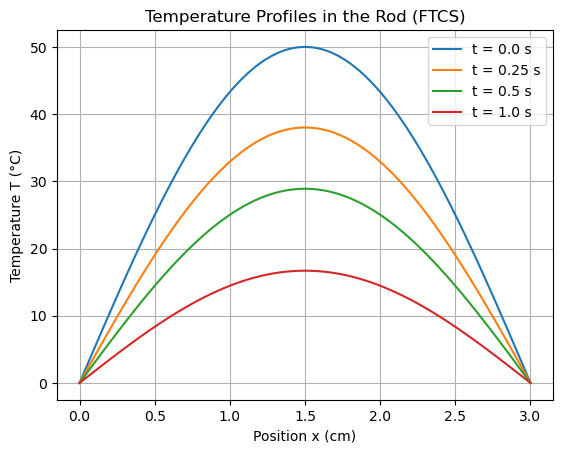

In [3]:
alpha = 1.0               # cm^2/s
L = 3.0                   # cm
t_initial = 0.0
t_final = 1.0             # s
T_boundary = 0.0              # ice-bath temperature at both ends (deg C)
x_values = np.arange(0.0, L + x_step / 2, x_step)
t_values = np.arange(t_initial, t_final + t_step / 2, t_step)

# Row n of T_values holds the temperature profile at time t_n
T_values = np.zeros((len(t_values), len(x_values)))
T_values[0] = 50.0 * np.sin(np.pi * x_values / L)
T_values[0, 0] = T_boundary
T_values[0, -1] = T_boundary

for n in range(len(t_values) - 1):
    # Interior points use the FTCS update
    for i in range(1, len(x_values) - 1):
        T_values[n + 1, i] = T_values[n, i] + r * (T_values[n, i + 1] - 2 * T_values[n, i] + T_values[n, i - 1])

    # Both ends stay in the ice bath
    T_values[n + 1, 0] = T_boundary
    T_values[n + 1, -1] = T_boundary

# Surface plot: using every 50th time row keeps the figure small
figure_3d = go.Figure()
figure_3d.add_trace(go.Surface(x=x_values, y=t_values[::50], z=T_values[::50]))
figure_3d.update_layout(
    title="Temperature in the Rod, T(t, x)",
    scene=dict(xaxis_title="x (cm)", yaxis_title="t (s)", zaxis_title="T (°C)")
)
figure_3d.show()

t_plot_values = [0.0, 0.25, 0.5, 1.0]  # s

plt.figure()
for t_plot in t_plot_values:
    n = int(round(t_plot / t_step))  # row index for this time
    plt.plot(x_values, T_values[n], label=f"t = {t_plot} s")
plt.title("Temperature Profiles in the Rod (FTCS)")
plt.xlabel("Position x (cm)")
plt.ylabel("Temperature T (°C)")
plt.legend()
plt.grid(True)
plt.show()

Heat conducts out through both cold ends, so the rod cools while the profile keeps its sine shape. The peak temperature at the center drops from 50 °C to about 16.7 °C at 1 s.

### Question 1.3

The analytical solution of this problem is

$$
T(t,x) = 50 \sin\left(\frac{\pi x}{L}\right) \exp\left(-\frac{\alpha \pi^2 t}{L^2}\right)
$$

Evaluate the analytical solution on the same grid and plot the absolute error between the FTCS and analytical temperatures versus $x$ at $t = 0.25$, 0.5, and 1.0 s. Print the maximum absolute error at $t = 1$ s, in °C.

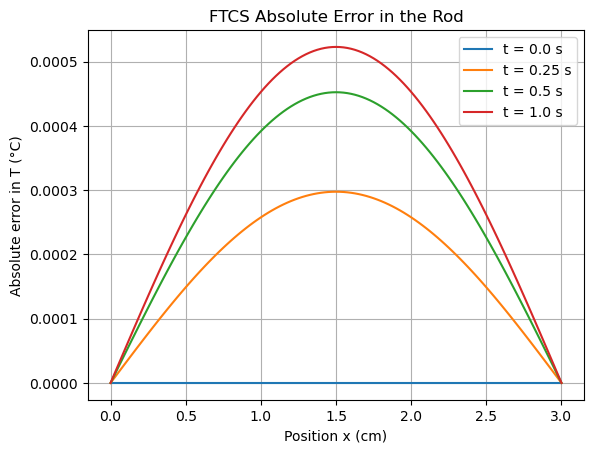

Maximum absolute error at t = 1.00 s: 5.23e-04 °C


In [4]:
plt.figure()
for t_plot in t_plot_values:
    n = int(round(t_plot / t_step))  # row index for this time
    T_exact_values = 50.0 * np.sin(np.pi * x_values / L) * np.exp(-alpha * np.pi**2 * t_values[n] / L**2)
    T_error_values = np.abs(T_values[n] - T_exact_values)
    plt.plot(x_values, T_error_values, label=f"t = {t_plot} s")
plt.title("FTCS Absolute Error in the Rod")
plt.xlabel("Position x (cm)")
plt.ylabel("Absolute error in T (°C)")
plt.legend()
plt.grid(True)
plt.show()

T_exact_final_values = 50.0 * np.sin(np.pi * x_values / L) * np.exp(-alpha * np.pi**2 * t_values[-1] / L**2)
max_error = np.max(np.abs(T_values[-1] - T_exact_final_values))
print(f"Maximum absolute error at t = {t_values[-1]:.2f} s: {max_error:.2e} °C")

The error is largest at the center of the rod and zero at the fixed ends. It grows slowly as the error from each time step accumulates, but at 1 s it is only about $5 \times 10^{-4}$ °C, far smaller than the 16.7 °C center temperature.

## Part 2: Pressure Waves in a Pipeline Between Two Tanks

A sudden pump or valve upset in a liquid pipeline sends pressure waves along the pipe. This is called water hammer, and the pressure spikes can damage pipes and fittings. Consider a pipe of length $L = 30$ m connecting two large tanks held at 3 bar and 1 bar (gauge), with a wave speed of $c = 1000$ m/s in the liquid. Before the upset, the pressure falls linearly from 3 bar to 1 bar along the pipe. At $t = 0$, the upset adds a pressure bump of $0.5 \sin(\pi x / L)$ bar on top of this profile, and the bump starts from rest. The gauge pressure $p(t,x)$ in bar satisfies the wave equation

$$
\frac{\partial^2 p}{\partial t^2} = c^2 \frac{\partial^2 p}{\partial x^2}
$$

$$
p(t,0) = 3, \qquad p(t,L) = 1, \qquad p(0,x) = 3 - \frac{2x}{L} + 0.5 \sin\left(\frac{\pi x}{L}\right), \qquad \frac{\partial p}{\partial t}(0,x) = 0
$$

Centered differences in both time and space give

$$
p_i^{n+1} = 2p_i^n - p_i^{n-1} + \lambda^2\left(p_{i+1}^n - 2p_i^n + p_{i-1}^n\right), \qquad \lambda = \frac{c \Delta t}{\Delta x}
$$

where $\lambda$ is the Courant number. As in Part 1, `p_values[n, i]` stores $p_i^n$. This update needs two earlier time levels, so the first step uses the initial rate $v_0(x) = \partial p / \partial t$ at $t = 0$ instead:

$$
p_i^1 = p_i^0 + \Delta t \, v_0(x_i) + \frac{\lambda^2}{2}\left(p_{i+1}^0 - 2p_i^0 + p_{i-1}^0\right)
$$

### Question 2.1

The explicit wave scheme is stable when $\lambda \leq 1$ (the CFL condition). This gives the largest stable time step

$$
\Delta t_{\mathrm{max}} = \frac{\Delta x}{c}
$$

As in Question 1.1, set $\Delta t = f \, \Delta t_{\mathrm{max}}$. For the wave scheme, this choice gives $\lambda = f$.

Use 201 grid points along the pipe and a stability fraction $f = 0.8$. Compute and print $\Delta x$ in m, $\Delta t_{\mathrm{max}}$ and $\Delta t$ in s, and $\lambda$.

In [5]:
c = 1000.0                # wave speed (m/s)
L = 30.0                  # pipe length (m)
n_x = 201                 # number of grid points
t_final = 0.06            # s
stability_fraction = 0.8

x_step = L / (n_x - 1)                       # m
t_step_max = x_step / c                      # largest stable time step (s)
t_step = stability_fraction * t_step_max     # time step we actually use (s)
courant_number = c * t_step / x_step         # lambda

print(f"x_step = {x_step:.4f} m")
print(f"t_step_max = {t_step_max:.3e} s")
print(f"t_step = {t_step:.3e} s")
print(f"Courant number lambda = {courant_number:.3f}")

x_step = 0.1500 m
t_step_max = 1.500e-04 s
t_step = 1.200e-04 s
Courant number lambda = 0.800


With $f = 0.8$, the Courant number is $\lambda = 0.8$, below the CFL limit of 1. Here $\Delta t_{\mathrm{max}}$ scales with $\Delta x$ instead of $\Delta x^2$, so refining the grid costs fewer extra time steps than it does for the heat equation.

### Question 2.2

Use the grid and time step from Question 2.1. Compute the first step $p^1$ with $v_0(x) = 0$, then march the centered update to $t = 0.06$ s (one full period $2L/c$), holding the pressure at 3 bar at $x = 0$ and 1 bar at $x = L$. Make a surface plot of $p(t,x)$, and plot $p$ versus $x$ at $t = 0$, 0.012, 0.024, and 0.03 s.

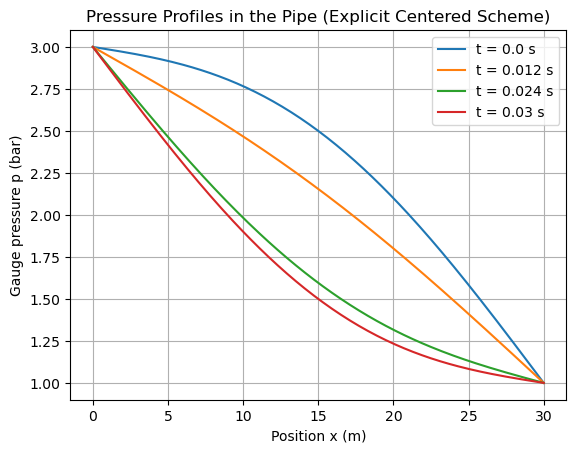

In [6]:
c = 1000.0                # m/s
L = 30.0                  # m
t_initial = 0.0
t_final = 0.06            # s
p_left = 3.0              # tank pressure at x = 0 (bar gauge)
p_right = 1.0             # tank pressure at x = L (bar gauge)
x_values = np.arange(0.0, L + x_step / 2, x_step)
t_values = np.arange(t_initial, t_final + t_step / 2, t_step)

# Row n of p_values holds the pressure profile at time t_n
p_values = np.zeros((len(t_values), len(x_values)))
p_values[0] = 3.0 - 2.0 * x_values / L + 0.5 * np.sin(np.pi * x_values / L)
p_values[0, 0] = p_left
p_values[0, -1] = p_right

v_initial_values = np.zeros(len(x_values))  # dp/dt at t = 0 (bar/s): the bump starts from rest

# First step uses the initial rate instead of an earlier time level
for i in range(1, len(x_values) - 1):
    p_values[1, i] = (p_values[0, i] + t_step * v_initial_values[i]
                      + 0.5 * courant_number**2 * (p_values[0, i + 1] - 2 * p_values[0, i] + p_values[0, i - 1]))
p_values[1, 0] = p_left
p_values[1, -1] = p_right

# Remaining steps use the centered update
for n in range(1, len(t_values) - 1):
    for i in range(1, len(x_values) - 1):
        p_values[n + 1, i] = (2 * p_values[n, i] - p_values[n - 1, i]
                              + courant_number**2 * (p_values[n, i + 1] - 2 * p_values[n, i] + p_values[n, i - 1]))

    # Both tanks hold their pressures
    p_values[n + 1, 0] = p_left
    p_values[n + 1, -1] = p_right

# Surface plot: using every 5th time row keeps the figure small
figure_3d = go.Figure()
figure_3d.add_trace(go.Surface(x=x_values, y=t_values[::5], z=p_values[::5]))
figure_3d.update_layout(
    title="Pressure in the Pipe, p(t, x)",
    scene=dict(xaxis_title="x (m)", yaxis_title="t (s)", zaxis_title="p (bar)")
)
figure_3d.show()

t_plot_values = [0.0, 0.012, 0.024, 0.03]  # s

plt.figure()
for t_plot in t_plot_values:
    n = int(round(t_plot / t_step))  # row index for this time
    plt.plot(x_values, p_values[n], label=f"t = {t_plot} s")
plt.title("Pressure Profiles in the Pipe (Explicit Centered Scheme)")
plt.xlabel("Position x (m)")
plt.ylabel("Gauge pressure p (bar)")
plt.legend()
plt.grid(True)
plt.show()

The ends stay at 3 bar and 1 bar, and the bump oscillates about the straight-line profile between them without losing amplitude. The bump is fully inverted at $t = 0.03$ s, half a period, and returns to its initial shape at $t = 0.06$ s.

### Question 2.3

The analytical solution of this problem is

$$
p(t,x) = 3 - \frac{2x}{L} + 0.5 \sin\left(\frac{\pi x}{L}\right) \cos\left(\frac{\pi c t}{L}\right)
$$

Evaluate the analytical solution on the same grid and plot the absolute error between the numerical and analytical pressures versus $x$ at $t = 0.012$, 0.024, and 0.03 s. Print the maximum absolute error over all time steps, in bar.

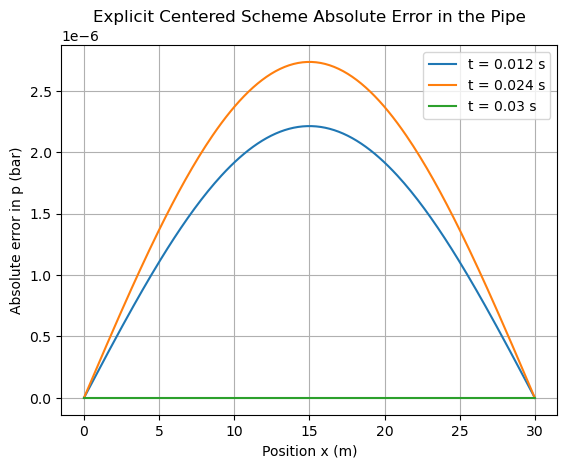

Maximum absolute error over all time steps: 8.91e-06 bar


In [7]:
t_plot_values = [0.012, 0.024, 0.03]  # s

plt.figure()
for t_plot in t_plot_values:
    n = int(round(t_plot / t_step))  # row index for this time
    p_exact_values = 3.0 - 2.0 * x_values / L + 0.5 * np.sin(np.pi * x_values / L) * np.cos(np.pi * c * t_values[n] / L)
    p_error_values = np.abs(p_values[n] - p_exact_values)
    plt.plot(x_values, p_error_values, label=f"t = {t_plot} s")
plt.title("Explicit Centered Scheme Absolute Error in the Pipe")
plt.xlabel("Position x (m)")
plt.ylabel("Absolute error in p (bar)")
plt.legend()
plt.grid(True)
plt.show()

# Largest error over every time step
max_error = 0.0
for n in range(len(t_values)):
    p_exact_values = 3.0 - 2.0 * x_values / L + 0.5 * np.sin(np.pi * x_values / L) * np.cos(np.pi * c * t_values[n] / L)
    error = np.max(np.abs(p_values[n] - p_exact_values))
    if error > max_error:
        max_error = error
print(f"Maximum absolute error over all time steps: {max_error:.2e} bar")

The error is zero at both tanks and largest at the center of the pipe. It is nearly zero at $t = 0.03$ s because the bump is at a turning point, where a small timing error in the wave barely changes $p$. The largest error over all time steps is about $9 \times 10^{-6}$ bar, so the scheme is very accurate on this grid.